## feature extraction

## The curse of dimensionality.

## What is dimensionality?
Each feature in your dataset is one dimension.
Example: A dataset with 10 columns has 10 features.

High dimensions cause problems.

## Why high dimensions cause problems. 
In high dimensions, distances loose meaning

### Prinicipal Component Analysis
#### What are principal components.


In [2]:
# Loading data
from sklearn.datasets import load_digits
digits = load_digits()


In [3]:
# Separate Features and Targets
X = digits.data
y = digits.target


In [4]:
# Scaling

from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)



In [5]:
# PCA - Principal Components
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_scaled)


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [6]:
import numpy as np
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

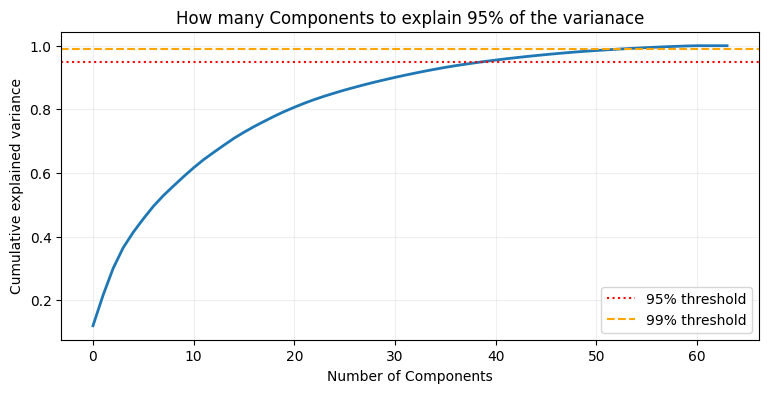

In [7]:
# Plotting
import matplotlib.pyplot as plt

plt.figure(figsize = (9,4))
plt.plot(cumvar, linewidth = 2)
plt.axhline(0.95, color='red', linestyle=':', label='95% threshold')
plt.axhline(0.99, color='orange', linestyle="--",label='99% threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative explained variance')
plt.title('How many Components to explain 95% of the varianace')
plt.legend()
plt.grid(alpha=0.2)
plt.show()



In [8]:
# Finding The exact number of components for 95%
n_95 = np.argmax(cumvar>=0.95) + 1
print(f'Components for 95% variance: {n_95} out of 64')

Components for 95% variance: 40 out of 64


In [9]:
# Spltting Data
X = digits.data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y ,test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train =scaler.fit_transform(X_train)
y_test =scaler.transform(X_test)

In [10]:
# fit PCA on training only
pca_train = PCA(n_components=0.95)

X_train_r = pca_train.fit_transform(X_train)
X_test_r = pca_train.transform(X_test)

In [11]:
X_train_r.shape

(1437, 40)

In [26]:
# KNN without PCA
import time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

t0 = time.time()
knn =KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)

t1 = time.time()

acc_original = accuracy_score(y_test, pred)

print("Original data KNN")
print(f"Accuracy: {acc_original:.3f}")
print(f"Time: {t1 -t0:.4f} sec")

Original data KNN
Accuracy: 0.019
Time: 0.0099 sec


In [ ]:
# KNN with PCA 

t0 = time.time()
knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train, y_train)
pred_pca = knn_pca.predict(X_test)

t1 = time.time()

acc_pca = accuracy_score(y_test, pred_pca)

print("KNN (PCA reduced)")
print(f"Accuracy: {acc_pca:.3f}")
print(f"Time: {t1 -t0:.4f} sec")


KNN (PCA reduced)
Accuracy: 0.019
Time: 0.0093 sec


In [34]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled)
print(f'Variance explained by 2 components: {pca_2d.explained_variance_ratio_.sum():.1%} ')



Variance explained by 2 components: 21.6% 


In [27]:
X_2d.shape

(1797, 2)

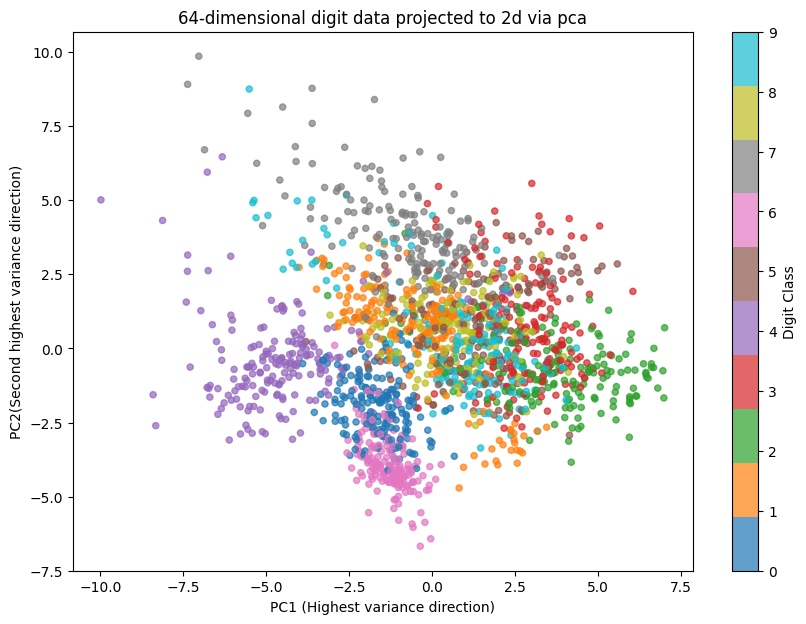

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y ,cmap = 'tab10', alpha=0.7, s=20)
plt.colorbar(scatter, label='Digit Class')

plt.title('64-dimensional digit data projected to 2d via pca')
plt.ylabel('PC2(Second highest variance direction)')
plt.xlabel('PC1 (Highest variance direction)')
plt.show()

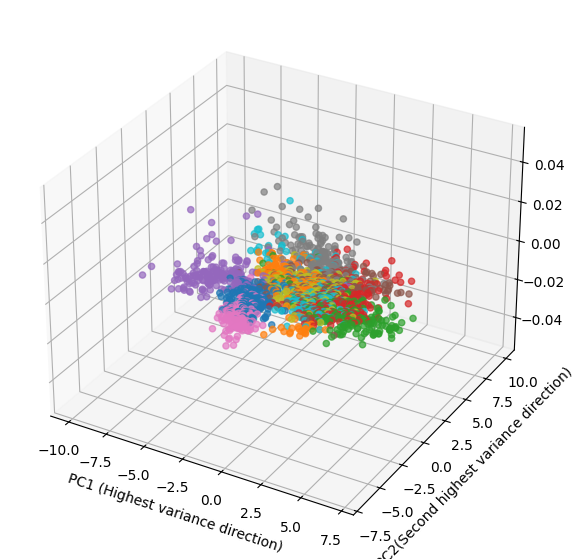

In [44]:
# 3D- PLOT
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
 
fig = plt.figure(figsize= (10, 7))
ax = fig.add_subplot(111, projection= '3d')
 
scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap= 'tab10', alpha = 0.7, s=20)
plt.xlabel('PC1 (Highest variance direction)')
plt.ylabel('PC2(Second highest variance direction)')
plt.show()